# Gold forecasting with Prophet

Prophet fits log gold prices with trend, weekly and yearly seasonality.
Gold-derived regressors are excluded. External regressors use their origin-time values throughout
each fixed-origin forecast. These are conditional persistence scenarios, not known future factors.

Run notebook 01 first. Review the shared audit and release assumptions before interpreting errors.

In [1]:
from pathlib import Path
import os
# Limit CPU threads before importing optional numerical/model libraries.
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from gold_common_utils import ROOT, load_config
# Load the shared experiment configuration.
cfg = load_config()
pd.set_option('display.max_columns', 20)
print('Project:', ROOT)
print('Target:', cfg['target_name'], '| horizons:', cfg['horizons'])

Project: /home/kosala/git-repos/exps/gold_forecasting
Target: Kitco Price (USD) | horizons: [1, 5, 20]


## 1. Load the shared panel and evaluation contract

In [2]:
from gold_common_utils import load_prepared, feature_columns, forecast_origins, metrics
from gold_model_utils import (DEFAULT_TRIALS, run_cross_validation, evaluate_holdout,
                              refit_and_forecast, fit_model, predict_model)
KIND = 'prophet'
# Reuse the processed data and folds created by notebook 01.
panel, features, folds = load_prepared()
display(folds)
print('Observed target:', panel.y.notna().sum())

,fold,cutoff,stop
0,cv_1,2175,2301
1,cv_2,2301,2427
2,cv_3,2427,2553
3,cv_4,2553,2679
4,cv_5,2679,2805
5,holdout,2805,3057


Observed target: 2646


## 2. Inspect input feature groups and candidate settings
`gold_only` establishes whether external factors improve an already useful gold-history model.
The initial search is intentionally small; expand it using development results only.
All candidate selection uses earlier inner validation. Read the adapters in `gold_model_utils.py`
for the explicit training and prediction logic.

In [3]:
# Show the exact candidates and the feature columns used per group.
trials = [dict(trial) for trial in DEFAULT_TRIALS[KIND]]
display(pd.DataFrame(trials))
for group in ['gold_only', 'external']:
    print(group, feature_columns(features, group, KIND))
# Change this local list to add candidates; keep comparable GRU/LSTM budgets.

,group,changepoint_prior_scale
0,gold_only,0.05
1,external,0.05
2,external,0.20


gold_only []
external ['dxy', 'fed', 'yield10', 'cpi_yoy', 'gpr_ma7', 'brent_spot', 'wti']


## 3. Inspect observed target and regressor coverage

,missing_fraction
dxy,0.000000
fed,0.000000
yield10,0.000000
cpi_yoy,0.005232
gpr_ma7,0.000000
brent_spot,0.000000
wti,0.000000


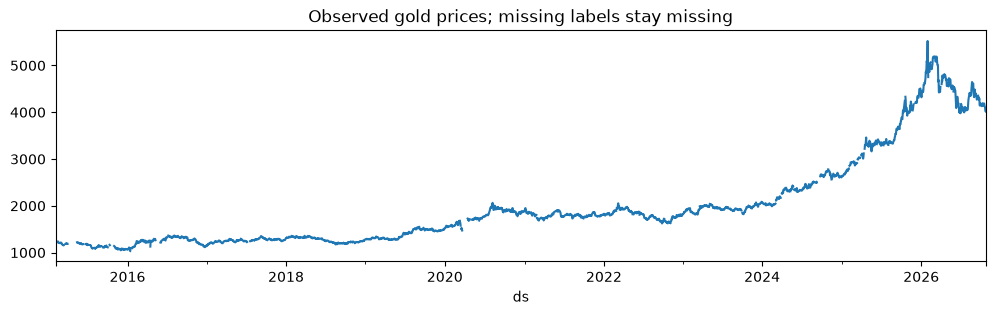

In [4]:
# Confirm external regressors are available at each forecast origin.
columns = feature_columns(features, 'external', KIND)
display(features[columns].isna().mean().rename('missing_fraction').to_frame())
panel.y.plot(figsize=(12, 3), title='Observed gold prices; missing labels stay missing')
plt.show()

## 4. Run nested walk-forward development evaluation
This cell performs actual training and may take time. Each fold reports inner candidate scores,
selects a configuration, refits it, and predicts the outer block. Forecasting uses only information
available at each origin. Outer labels are used only for scoring.

For a quick installation check, use one fold and one candidate. Restore the full settings before
comparing models or making performance claims.

In [5]:
# Full defaults: five outer folds and all candidates above.
cv_folds = folds
# Full training; results are checkpointed to artifacts/<kind>/ after each fold.
cv_predictions, cv_metrics, selections = run_cross_validation(
    KIND, panel, features, cv_folds, cfg, trials=trials)
display(cv_metrics)
display(selections)

prophet: cv_1; train through 2023-06-08


Importing plotly failed. Interactive plots will not work.
/home/kosala/git-repos/exps/gold_prediction/env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
14:08:27 - cmdstanpy - INFO - Chain [1] start processing
14:08:28 - cmdstanpy - INFO - Chain [1] done processing


  candidate 1/3: inner MAE=96.584


14:08:28 - cmdstanpy - INFO - Chain [1] start processing
14:08:31 - cmdstanpy - INFO - Chain [1] done processing


  candidate 2/3: inner MAE=54.279


14:08:31 - cmdstanpy - INFO - Chain [1] start processing
14:08:33 - cmdstanpy - INFO - Chain [1] done processing


... (32 outputs left out)

  candidate 3/3: inner MAE=127.964


14:09:03 - cmdstanpy - INFO - Chain [1] start processing
14:09:05 - cmdstanpy - INFO - Chain [1] done processing


,model,fold,horizon,n,MAE,RMSE,MAPE,MASE,baseline_MAE,skill_vs_persistence
0,prophet,cv_1,1,5,36.619167,54.734617,1.850046,3.804878,9.580000,-2.822460
1,prophet,cv_1,5,5,35.385345,49.524756,1.798560,3.676679,19.620000,-0.803534
2,prophet,cv_1,20,4,36.693062,49.672282,1.865918,3.812556,22.650000,-0.620003
3,prophet,cv_2,1,5,93.389570,111.627646,4.545434,9.745008,11.254000,-7.298345
4,prophet,cv_2,5,4,91.337430,113.358529,4.461577,9.530872,46.242500,-0.975184
5,prophet,cv_2,20,6,134.043219,156.829129,6.142310,13.987132,76.023333,-0.763185
6,prophet,cv_3,1,4,258.734312,287.779256,10.188900,26.516004,13.507500,-18.154863
7,prophet,cv_3,5,4,215.996715,272.872750,8.429449,22.136105,26.272500,-7.221399
8,prophet,cv_3,20,4,226.704686,248.131213,9.043021,23.233495,55.287500,-3.100469
9,prophet,cv_4,1,4,84.285716,88.457389,3.061701,8.383519,26.072500,-2.232744


,candidate,inner_MAE,params,fold
0,0,96.583550,"{""group"": ""gold_only"", ""changepoint_prior_scal...",cv_1
1,1,54.279142,"{""group"": ""external"", ""changepoint_prior_scale...",cv_1
2,2,65.012182,"{""group"": ""external"", ""changepoint_prior_scale...",cv_1
3,0,150.021834,"{""group"": ""gold_only"", ""changepoint_prior_scal...",cv_2
4,1,36.232525,"{""group"": ""external"", ""changepoint_prior_scale...",cv_2
5,2,39.438968,"{""group"": ""external"", ""changepoint_prior_scale...",cv_2
6,0,95.354412,"{""group"": ""gold_only"", ""changepoint_prior_scal...",cv_3
7,1,106.256740,"{""group"": ""external"", ""changepoint_prior_scale...",cv_3
8,2,112.283134,"{""group"": ""external"", ""changepoint_prior_scale...",cv_3
9,0,233.811904,"{""group"": ""gold_only"", ""changepoint_prior_scal...",cv_4


## 5. Review errors by horizon, baseline skill, and prediction bias

,MAE,RMSE,MAPE,MASE,skill_vs_persistence
horizon,,,,,
1,118.843152,139.068136,4.587412,11.986039,-6.568094
5,130.778144,160.627579,4.842481,13.122566,-2.092965
20,137.394878,167.634261,5.063176,13.817877,-0.881585


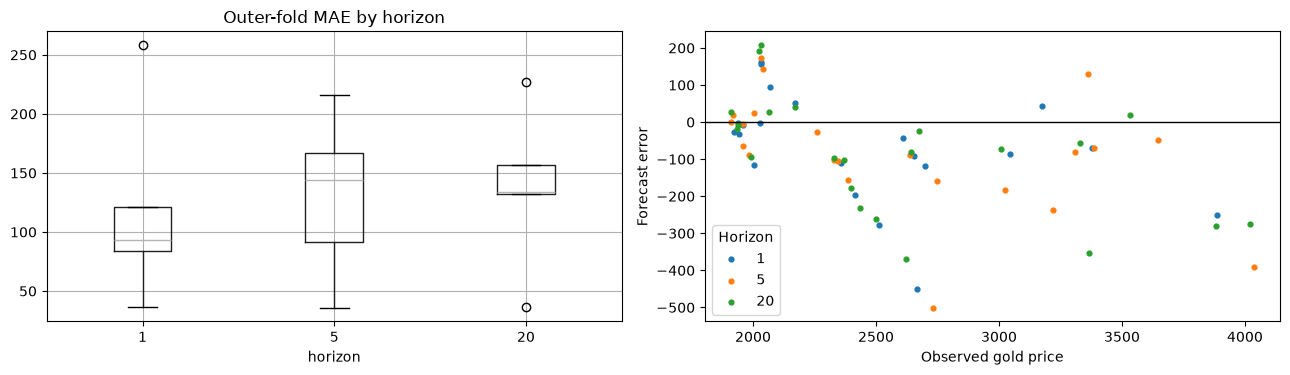

In [6]:
# Summarize outer error by horizon and check prediction bias per model.
display(cv_metrics.groupby('horizon')[['MAE', 'RMSE', 'MAPE', 'MASE', 'skill_vs_persistence']].mean())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cv_metrics.boxplot(column='MAE', by='horizon', ax=axes[0])
axes[0].set_title('Outer-fold MAE by horizon')
for horizon, group in cv_predictions.groupby('horizon'):
    observed = group.dropna(subset=['actual'])
    axes[1].scatter(observed.actual, observed.prediction - observed.actual, s=12, label=str(horizon))
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_xlabel('Observed gold price')
axes[1].set_ylabel('Forecast error')
axes[1].legend(title='Horizon')
plt.suptitle('')
plt.tight_layout()

## 6. Lock the final configuration and evaluate the untouched holdout
The default is off so you can review development results first. Set
`final_holdout_enabled` to true in `config.json` when ready. This is an experiment guard,
not a request for additional permission. The function chooses parameters using development
history, records them before scoring, and preserves existing holdout results.

In [7]:
# Load the shared experiment configuration.
cfg = load_config()
# Holdout runs once, and parameters are locked before its results are scored.
if cfg['final_holdout_enabled']:
    holdout_predictions, holdout_metrics, locked_parameters = evaluate_holdout(
        KIND, panel, features, folds, cfg, trials=trials)
    display(holdout_metrics)
    display(locked_parameters)
else:
    print('Holdout not evaluated. Development predictions remain available for review.')

Holdout not evaluated. Development predictions remain available for review.


## 7. Refit the locked model and generate future forecasts
Run after the final holdout stage. The forecast starts from the latest observed gold quote.
Only the configured horizons are returned. Future actual external factors are not supplied.
Artifacts include the fitted model, input feature names, preprocessing where applicable,
locked configuration, predictions and metrics. No calibrated uncertainty intervals are claimed.

In [8]:
locked = ROOT / 'artifacts' / KIND / 'locked_parameters.json'
if cfg['final_holdout_enabled'] and locked.exists():
    # Refit reuses the locked configuration from artifacts/<kind>/locked_parameters.json.
    future_forecast = refit_and_forecast(KIND, panel, features, cfg)
    display(future_forecast)
else:
    print('Final refit waits for the parameter-lock stage.')

Final refit waits for the parameter-lock stage.
